# Cite Claude's answers at the exact spot in the PDF

This notebook sends a PDF to Claude with citations enabled, locates each cited passage on the page with PyMuPDF, highlights it, and exports coordinates for a web viewer.

Requires `ANTHROPIC_API_KEY` in the environment.

In [ ]:
%pip install -q pymupdf anthropic

## Sample document
Creates a two-page sample report. Replace `path` with your own PDF (it needs a text layer).

In [1]:
import pymupdf
doc = pymupdf.open()
p1 = """Acme Corporation Annual Report 2025

Financial highlights. Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. Operating margin improved to 18.4%, compared with 16.9% in the prior year. The company returned $350 million to shareholders through dividends and share repurchases.

Outlook. Management expects revenue growth of 8% to 10% in fiscal 2026, with continued invest-\nment in cloud infrastructure and data centers in Europe and Asia. Capital expenditure is expected to reach $600 million."""
p2 = """Risk factors. The company depends on a small number of large customers. In fiscal 2025, the three largest customers accounted for 31% of net revenue. The loss of any of these customers could materially affect results.

Supply chain disruptions in 2024 delayed shipments of hardware appliances by up to six weeks. These delays did not recur in 2025."""
for txt in (p1, p2):
    page = doc.new_page()
    page.insert_textbox(pymupdf.Rect(72, 72, 400, 760), txt, fontsize=11, fontname="helv")
doc.save("acme_annual_report.pdf")

path = "acme_annual_report.pdf"

## Grounding helpers

In [2]:
import re
import pymupdf


def locate(page, cited_text):
    """Return the quads of cited_text on a page, or [] if not found."""
    text = " ".join(cited_text.split())          # collapse whitespace and line breaks
    quads = page.search_for(text, quads=True)
    if quads:
        return quads
    return _locate_by_words(page, text)          # fallback for small differences


def _norm(word):
    return re.sub(r"[^\w%$.]", "", word).lower().rstrip(".")


def _locate_by_words(page, text):
    """Match the quote word by word, ignoring punctuation, case and hyphenation."""
    target = [_norm(w) for w in text.split() if _norm(w)]
    words = page.get_text("words", flags=pymupdf.TEXT_DEHYPHENATE)
    tokens = [(_norm(w[4]), pymupdf.Rect(w[:4])) for w in words]
    tokens = [t for t in tokens if t[0]]
    n = len(target)
    for i in range(len(tokens) - n + 1):
        if all(tokens[i + k][0] == target[k] for k in range(n)):
            return [r.quad for _, r in tokens[i:i + n]]
    return []


def ground_citations(response, docs):
    """Map each page_location citation in a Claude response to quads on the page.

    response: the Message returned by client.messages.create()
    docs: the PyMuPDF documents, in the order they were sent to Claude
    """
    results = []
    for block in response.content:
        if block.type != "text" or not getattr(block, "citations", None):
            continue
        for cit in block.citations:
            if cit.type != "page_location":
                continue
            doc = docs[cit.document_index]
            # Claude's page numbers are 1-based; end_page_number is exclusive
            for pno in range(cit.start_page_number - 1, cit.end_page_number - 1):
                quads = locate(doc[pno], cit.cited_text)
                if quads:
                    results.append({"claim": block.text, "cited_text": cit.cited_text,
                                    "doc": cit.document_index, "page": pno, "quads": quads})
                    break
            else:
                results.append({"claim": block.text, "cited_text": cit.cited_text,
                                "doc": cit.document_index, "page": None, "quads": []})
    return results


def highlight(docs, results):
    for r in results:
        if not r["quads"]:
            continue
        page = docs[r["doc"]][r["page"]]
        annot = page.add_highlight_annot(r["quads"])
        annot.set_info(content=r["claim"])
        annot.update()


def to_json(results, docs):
    """Page number (1-based) and normalized 0-1 box for each citation, for a web viewer."""
    out = []
    for r in results:
        item = {"claim": r["claim"], "cited_text": r["cited_text"], "found": bool(r["quads"])}
        if r["quads"]:
            page = docs[r["doc"]][r["page"]]
            box = pymupdf.Rect()
            for q in r["quads"]:
                box |= q.rect
            w, h = page.rect.width, page.rect.height
            item["page_number"] = r["page"] + 1
            item["box"] = [round(box.x0 / w, 4), round(box.y0 / h, 4),
                           round(box.x1 / w, 4), round(box.y1 / h, 4)]
        out.append(item)
    return out

## Ask Claude with citations enabled

In [5]:
import base64, pathlib
import anthropic

pdf_data = base64.standard_b64encode(pathlib.Path(path).read_bytes()).decode()

client = anthropic.Anthropic()
response = client.messages.create(
    model="claude-opus-5-5",
    max_tokens=1024,
    messages=[{
        "role": "user",
        "content": [
            {
                "type": "document",
                "source": {"type": "base64", "media_type": "application/pdf", "data": pdf_data},
                "title": "Acme Annual Report 2025",
                "citations": {"enabled": True},
            },
            {"type": "text", "text": "What were Acme's key financial results, and what risks does it report?"},
        ],
    }],
)

## Locate, highlight and export

In [6]:
import json

doc = pymupdf.open(path)
results = ground_citations(response, [doc])
highlight([doc], results)
doc.save("acme_highlighted.pdf")

for r in results:
    status = f"page {r['page'] + 1}" if r["quads"] else "NOT FOUND"
    print(f"{status:10} {r['cited_text'][:60]}")

print(json.dumps(to_json(results, [doc]), indent=2))

page 1     Net revenue increased 12% to $4.1 billion,
driven by growth
page 1     Operating
margin improved to 18.4%, compared with 16.9% in 
page 1     The company returned $350 million to shareholders through
d
NOT FOUND  Management expects revenue growth of 8% to 10% in
fiscal 20
page 1     Capital expenditure is expected to reach $600 million.
page 2     The company depends on a small number of large
customers. 
page 2     In fiscal 2025, the three largest customers accounted
for 3
page 2     The loss of any of these customers could
materially affect 
page 2     Supply chain disruptions in 2024 delayed shipments of hardwa
page 2     These delays did not recur in 2025.
[
  {
    "claim": "Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment.",
    "cited_text": "Net revenue increased 12% to $4.1 billion,\r\ndriven by growth in the enterprise software segment. ",
    "found": true,
    "page_number": 1,
    "box": [
      0.121,
      0.1241,

## Preview the first highlighted page

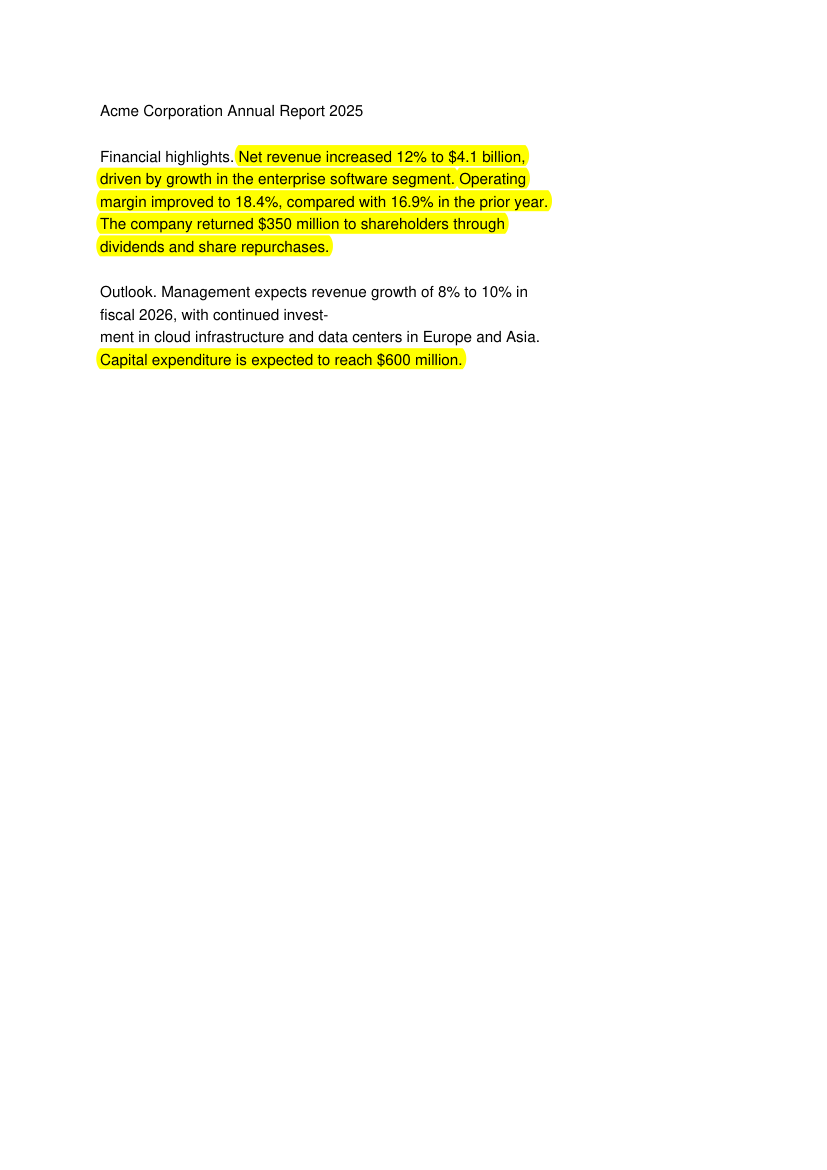

In [7]:
from IPython.display import Image
Image(doc[0].get_pixmap(dpi=100).tobytes("png"))